<div style="font-size: 36px; font-weight: bold;">Beginning</div>

In [145]:
%run basic_initialization.ipynb
plotFigs = True
saveFigs = True

Tue 29/09/26 01:12:00


<div style="font-size: 28px; font-weight: bold;">Data Preparation</div>

<div style="font-size: 28px; font-weight: bold;">Import Data and Check Data</div>

In [146]:
Datafile = 'flow_stress_table(31).txt'
datas = readTXTs(Datafile)
depspArray = getDepspArray(datas)
TArray = getTArray(datas)
numberofdatas= len(datas)
print('depspArray',depspArray,'contains',depspArray.shape[0],'data')
print('TArray',TArray,'contains',TArray.shape[0],'data')
print('total of',numberofdatas,'data')



depspArray [0.1 1. ] contains 2 data
TArray [ 950. 1000. 1050.] contains 3 data
total of 6 data


<div style="font-size: 28px; font-weight: bold;">Plot the datas</div>

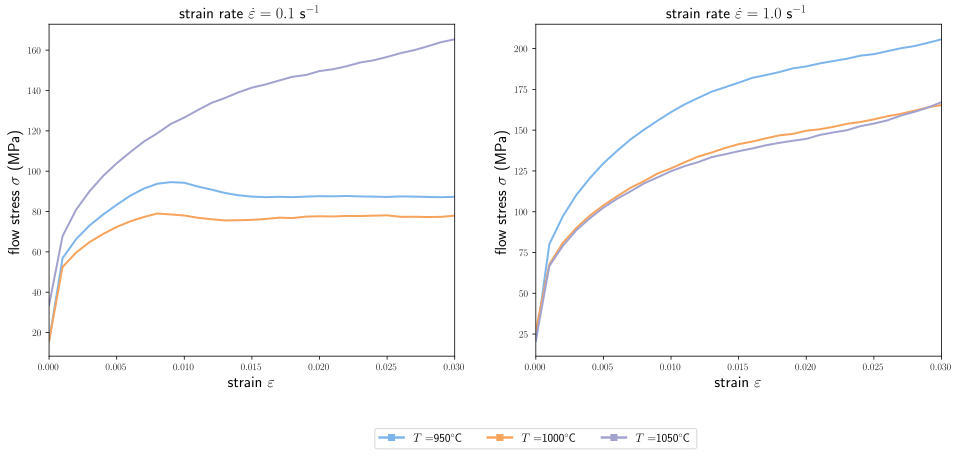

In [147]:
plotDatas(datas, filename='')

<div style="font-size: 28px; font-weight: bold;">ANN Basic Setting</div>

<div style="font-size: 28px; font-weight: bold;">data setting</div>


compute and replace $\dot\varepsilon$ by $\log(\frac{\dot\varepsilon}{\dot\varepsilon_0})$

Compute min and max of ranges

Computes ANNdata

In [148]:
deps0 = depspArray.min()
print('deps0=',deps0)

# since each noeds in the ANN computation should consider the T depsp strain, so expend the datas to shape of [n,4]
strain_data = np.linspace(0, 0.02 * int(len(datas[0][2])-1), num = len(datas[0][2]))
strain = np.asarray(strain_data)

allData = np.concatenate([
    np.column_stack([
        strain,                              # ε
        np.full(len(strain), d[0]),          # depsp
        np.full(len(strain), d[1]),          # T
        np.asarray(d[2])                     # σ
    ])
    for d in datas
])
print('Format of allData', allData.shape)
# change data 
#change strain_rate
deps0 = depspArray.min()
print('deps0=',deps0)
allData[:,1] = np.log(allData[:,1] / deps0)
# change to ann data
minData = allData.min(axis=0)
maxData = allData.max(axis=0)
rangeData = maxData - minData
annData = (allData - minData) / rangeData

# set input data and output data
annInput = annData[:,0:3]
annOutput = annData[:,3:4]
# quick look of the training data shape
annInput.shape, annOutput.shape



deps0= 0.1
Format of allData (186, 4)
deps0= 0.1


((186, 3), (186, 1))

<div style="font-size: 28px; font-weight: bold;">ANN structure</div>


In [149]:
# basic setting
models = []
convergence = []
convergences = []

activations =['sigmoid','tanh', 'relu', 'softplus', 'swish', 'exponential']
shapes = [16, 8]

loss = 'mean_squared_error'
optimizer = 'adam'

# model setting
for activation in activations:
    model = Sequential()
    name = str(3)
    layers = shapes if isinstance(shapes, list) else [shapes]
    for i, n in enumerate(layers):
        if i == 0:
            model.add(Dense(n, input_dim=3, activation=activation, name=f'hl-{i}'))
            name += '-'+str(n)
        else:
            model.add(Dense(n, activation=activation, name=f'hl-{i}'))
    name += '-' + str(n)
    model.add(Dense(1, name = 'output'))
    name += '-' + str(1) + '-' + activation
    model._name = name
    models.append(model)
    model.compile(loss = loss, optimizer = optimizer)   
    convergences.append([name, np.array([])])
    






make sure all the models have the same initial conditions

In [150]:
model0 = models[0]
for model in models:
    model.set_weights(model0.get_weights())

for model in models:
    model.summary()

Model: "3-16-8-1-sigmoid"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   


 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                (None, 8)                 136       
                                                                 
 output (Dense)              (None, 1)                 9         
                                                                 
Total params: 209
Trainable params: 209
Non-trainable params: 0
_________________________________________________________________
Model: "3-16-8-1-tanh"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                (None, 8)                 136       
                                                                 
 output (Dense)              (None, 1)                 

In [151]:
for convergence in convergences:
    print(convergence)

['3-16-8-1-sigmoid', array([], dtype=float64)]
['3-16-8-1-tanh', array([], dtype=float64)]
['3-16-8-1-relu', array([], dtype=float64)]
['3-16-8-1-softplus', array([], dtype=float64)]
['3-16-8-1-swish', array([], dtype=float64)]
['3-16-8-1-exponential', array([], dtype=float64)]


<div style="font-size: 28px; font-weight: bold;">ANN Training</div>


In [152]:
#basic setting
epochs = 601
maxIterations = 10
savePeriod = 1
annTraining = False
DataFile = "trained_models"
os.makedirs(DataFile, exist_ok=True)
print(convergences)

from sklearn.model_selection import train_test_split
x_train, x_valid, y_train, y_valid = train_test_split(annInput, annOutput, test_size = 0.25, shuffle = True)
x_train.shape, x_valid.shape, y_train.shape, y_valid.shape


[['3-16-8-1-sigmoid', array([], dtype=float64)], ['3-16-8-1-tanh', array([], dtype=float64)], ['3-16-8-1-relu', array([], dtype=float64)], ['3-16-8-1-softplus', array([], dtype=float64)], ['3-16-8-1-swish', array([], dtype=float64)], ['3-16-8-1-exponential', array([], dtype=float64)]]


((139, 3), (47, 3), (139, 1), (47, 1))

In [153]:

#train route
if annTraining:
    for model, convergence in zip(models, convergences):
        print("Start to train model:", model.name)
        lastMeanLoss = None
        for iteration in range(1, maxIterations + 1):
            history = model.fit(
                x_train, y_train,
                epochs=epochs,
                verbose=0,
                shuffle=True,
                validation_data=(x_valid, y_valid)
            )
            # Only keep the final loss of this full training run
            finalLoss = history.history['loss'][-1]
            convergence[1] = np.append(convergence[1],finalLoss)

            # Print one line per iteration
            if lastMeanLoss is None:
                print(f"Iteration {iteration}: final loss = {finalLoss:.6f}")
            else:
                print(f"Iteration {iteration}: final loss = {finalLoss:.6f} "
                      f"(reduction = {lastMeanLoss - finalLoss:.6f})")
            lastMeanLoss = finalLoss

            # Save every savePeriod iterations
            if iteration % savePeriod == 0:
                model.save(f"{DataFile}/{model.name}.h5")
                writeArrayH5(f"{DataFile}/{model.name}-conv.h5", "data", convergence[1])
                print(f"  saved at iteration {iteration}")

        # Final save
        model.save(f"{DataFile}/{model.name}.h5")
        WriteANNH5(f"{DataFile}/{model.name}-ANN.h5")
        print(f"End of training: {iteration} iterations x {epochs} epochs")
else:
    for model, convergence in zip(models, convergences):
        weightPath = f"{DataFile}/{model.name}.h5"
        convPath = f"{DataFile}/{model.name}-conv.h5"

        if os.path.exists(weightPath):
            try:
                model.load_weights(weightPath)
                print(f"Loaded weights: {weightPath}")
            except Exception as e:
                print(f"Failed to load weights for {model.name}: {e}")
        else:
            print(f"Missing weights file: {weightPath}")

        if os.path.exists(convPath):
            try:
                with h5py.File(convPath, "r") as hf:
                    if "data" in hf:
                        convergence[1] = hf["data"][:]
                        print(
                            f"Loaded convergence: {convPath} "
                            f"(shape={convergence[1].shape})"
                        )
                    else:
                        print(f"No 'data' key in {convPath}. Keys: {list(hf.keys())}")
            except Exception as e:
                print(f"Failed to read {convPath}: {e}")
        else:
            print(f"Missing convergence file: {convPath}")






Loaded weights: trained_models/3-16-8-1-sigmoid.h5
Loaded convergence: trained_models/3-16-8-1-sigmoid-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-tanh.h5
Loaded convergence: trained_models/3-16-8-1-tanh-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-relu.h5
Loaded convergence: trained_models/3-16-8-1-relu-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-softplus.h5
Loaded convergence: trained_models/3-16-8-1-softplus-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-swish.h5
Loaded convergence: trained_models/3-16-8-1-swish-conv.h5 (shape=(10,))
Loaded weights: trained_models/3-16-8-1-exponential.h5
Loaded convergence: trained_models/3-16-8-1-exponential-conv.h5 (shape=(10,))


convergence curve

In [154]:
# mean loss of different models
for convergence in convergences:
    print('%s %.3f x 10-6' %(convergence[0], 1e6*np.mean(convergence[1][-100:])))

3-16-8-1-sigmoid 4789.099 x 10-6
3-16-8-1-tanh 327.491 x 10-6
3-16-8-1-relu 93.595 x 10-6
3-16-8-1-softplus 2507.342 x 10-6
3-16-8-1-swish 594.960 x 10-6
3-16-8-1-exponential 1790.597 x 10-6


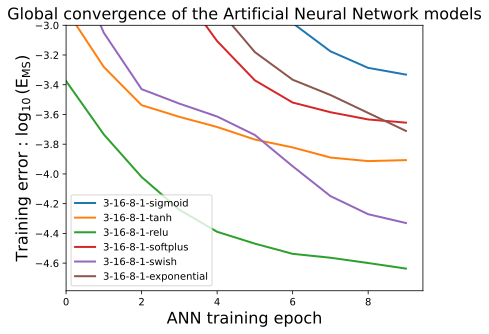

In [155]:
has_data = False
windowLength = 5
# plotDatas() enables usetex; matplotlib's default TeX preamble has no \text (needs amsmath).
plt.rcParams['text.usetex'] = False
for convergence in convergences:
    try:
        convergencef = savgol_filter(np.log10(convergence[1]), window_length=windowLength, polyorder=2)
        plt.plot(convergencef, label=convergence[0], linewidth=2)
        has_data = True
    except Exception as e:
        print(f"Error with {convergence[0]}: {e}")
        continue

if has_data:
    plt.ylim(None, -3)
    plt.xlim(0, None)
    plt.xlabel(r'ANN training epoch', fontsize=16)
    plt.ylabel(r'Training error : $\log_{10}\left(\mathrm{E}_\mathrm{MS}\right)$', fontsize=16)
    plt.title(r'Global convergence of the Artificial Neural Network models', fontsize=16)
    plt.legend()
    if saveFigs:
        plt.savefig("convergence.svg")
    plt.show()
else:
    print("No data to plot.")